<a href="https://colab.research.google.com/github/zrejasl90-ux/AI-class__ZRDL_FIME-2026/blob/main/Decision_tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

AF2_DATA_PROCESSING

Authors and ID:

Zianya Rejas de Luna.- 2106342.

Guillermo Treviño Saavedra.- 2042213.

Gabriel Eduardo Zárate Cruz.- 2122411.

Arath Alejandro Moreno Mendoza.- 2132070.

Schedule: Thursday (N3)

Course: Artificial Inteligence.

Ing. Daniel Isaías López Páez.

In [1]:

# 1. Load libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report


In [2]:

# 2. Load data

cancer = load_breast_cancer()

# Create the dataset
data = pd.DataFrame(cancer.data, columns=cancer.feature_names)

# Create the labels
labels = pd.Series(cancer.target)

# Display the first five rows
print("Dataset:")
display(data.head())

print("Dataset dimensions:", data.shape)

print("\nTarget classes:")
print(cancer.target_names)


Dataset:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Dataset dimensions: (569, 30)

Target classes:
['malignant' 'benign']


In [3]:

# 3. Data preprocessing

# Split the dataset into training and testing sets
train_data, test_data, train_labels, test_labels = train_test_split(
    data,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

# Display the dimensions of each dataset
print("Training data:", train_data.shape)
print("Training labels:", train_labels.shape)

print("\nTesting data:", test_data.shape)
print("Testing labels:", test_labels.shape)


Training data: (455, 30)
Training labels: (455,)

Testing data: (114, 30)
Testing labels: (114,)


In [4]:

# 4. Model selection and training

# Create the Decision Tree model
model = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

# Train the model
model.fit(train_data, train_labels)

print("Decision Tree model trained successfully!")


Decision Tree model trained successfully!


In [5]:

# 5. Model testing

# Make predictions using the testing data
predictions = model.predict(test_data)

print("Predictions:")
print(predictions)


Predictions:
[0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 1 1 1 1 0 0 1 1 1 0 0 1 1 1 1 1 1 0 0 0 1
 0 1 0 1 1 1 0 0 0 1 1 0 0 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 1 0 1 1 1 0 1 1 0
 0 0 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 0 1
 0 1 1]


In [6]:

# Calculate model accuracy
accuracy = accuracy_score(test_labels, predictions)

print("Model Accuracy:", accuracy)
print("Model Accuracy (%):", accuracy * 100)

# Generate classification report
print("\nClassification Report:")
print(classification_report(
    test_labels,
    predictions,
    target_names=cancer.target_names
))


Model Accuracy: 0.9122807017543859
Model Accuracy (%): 91.22807017543859

Classification Report:
              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



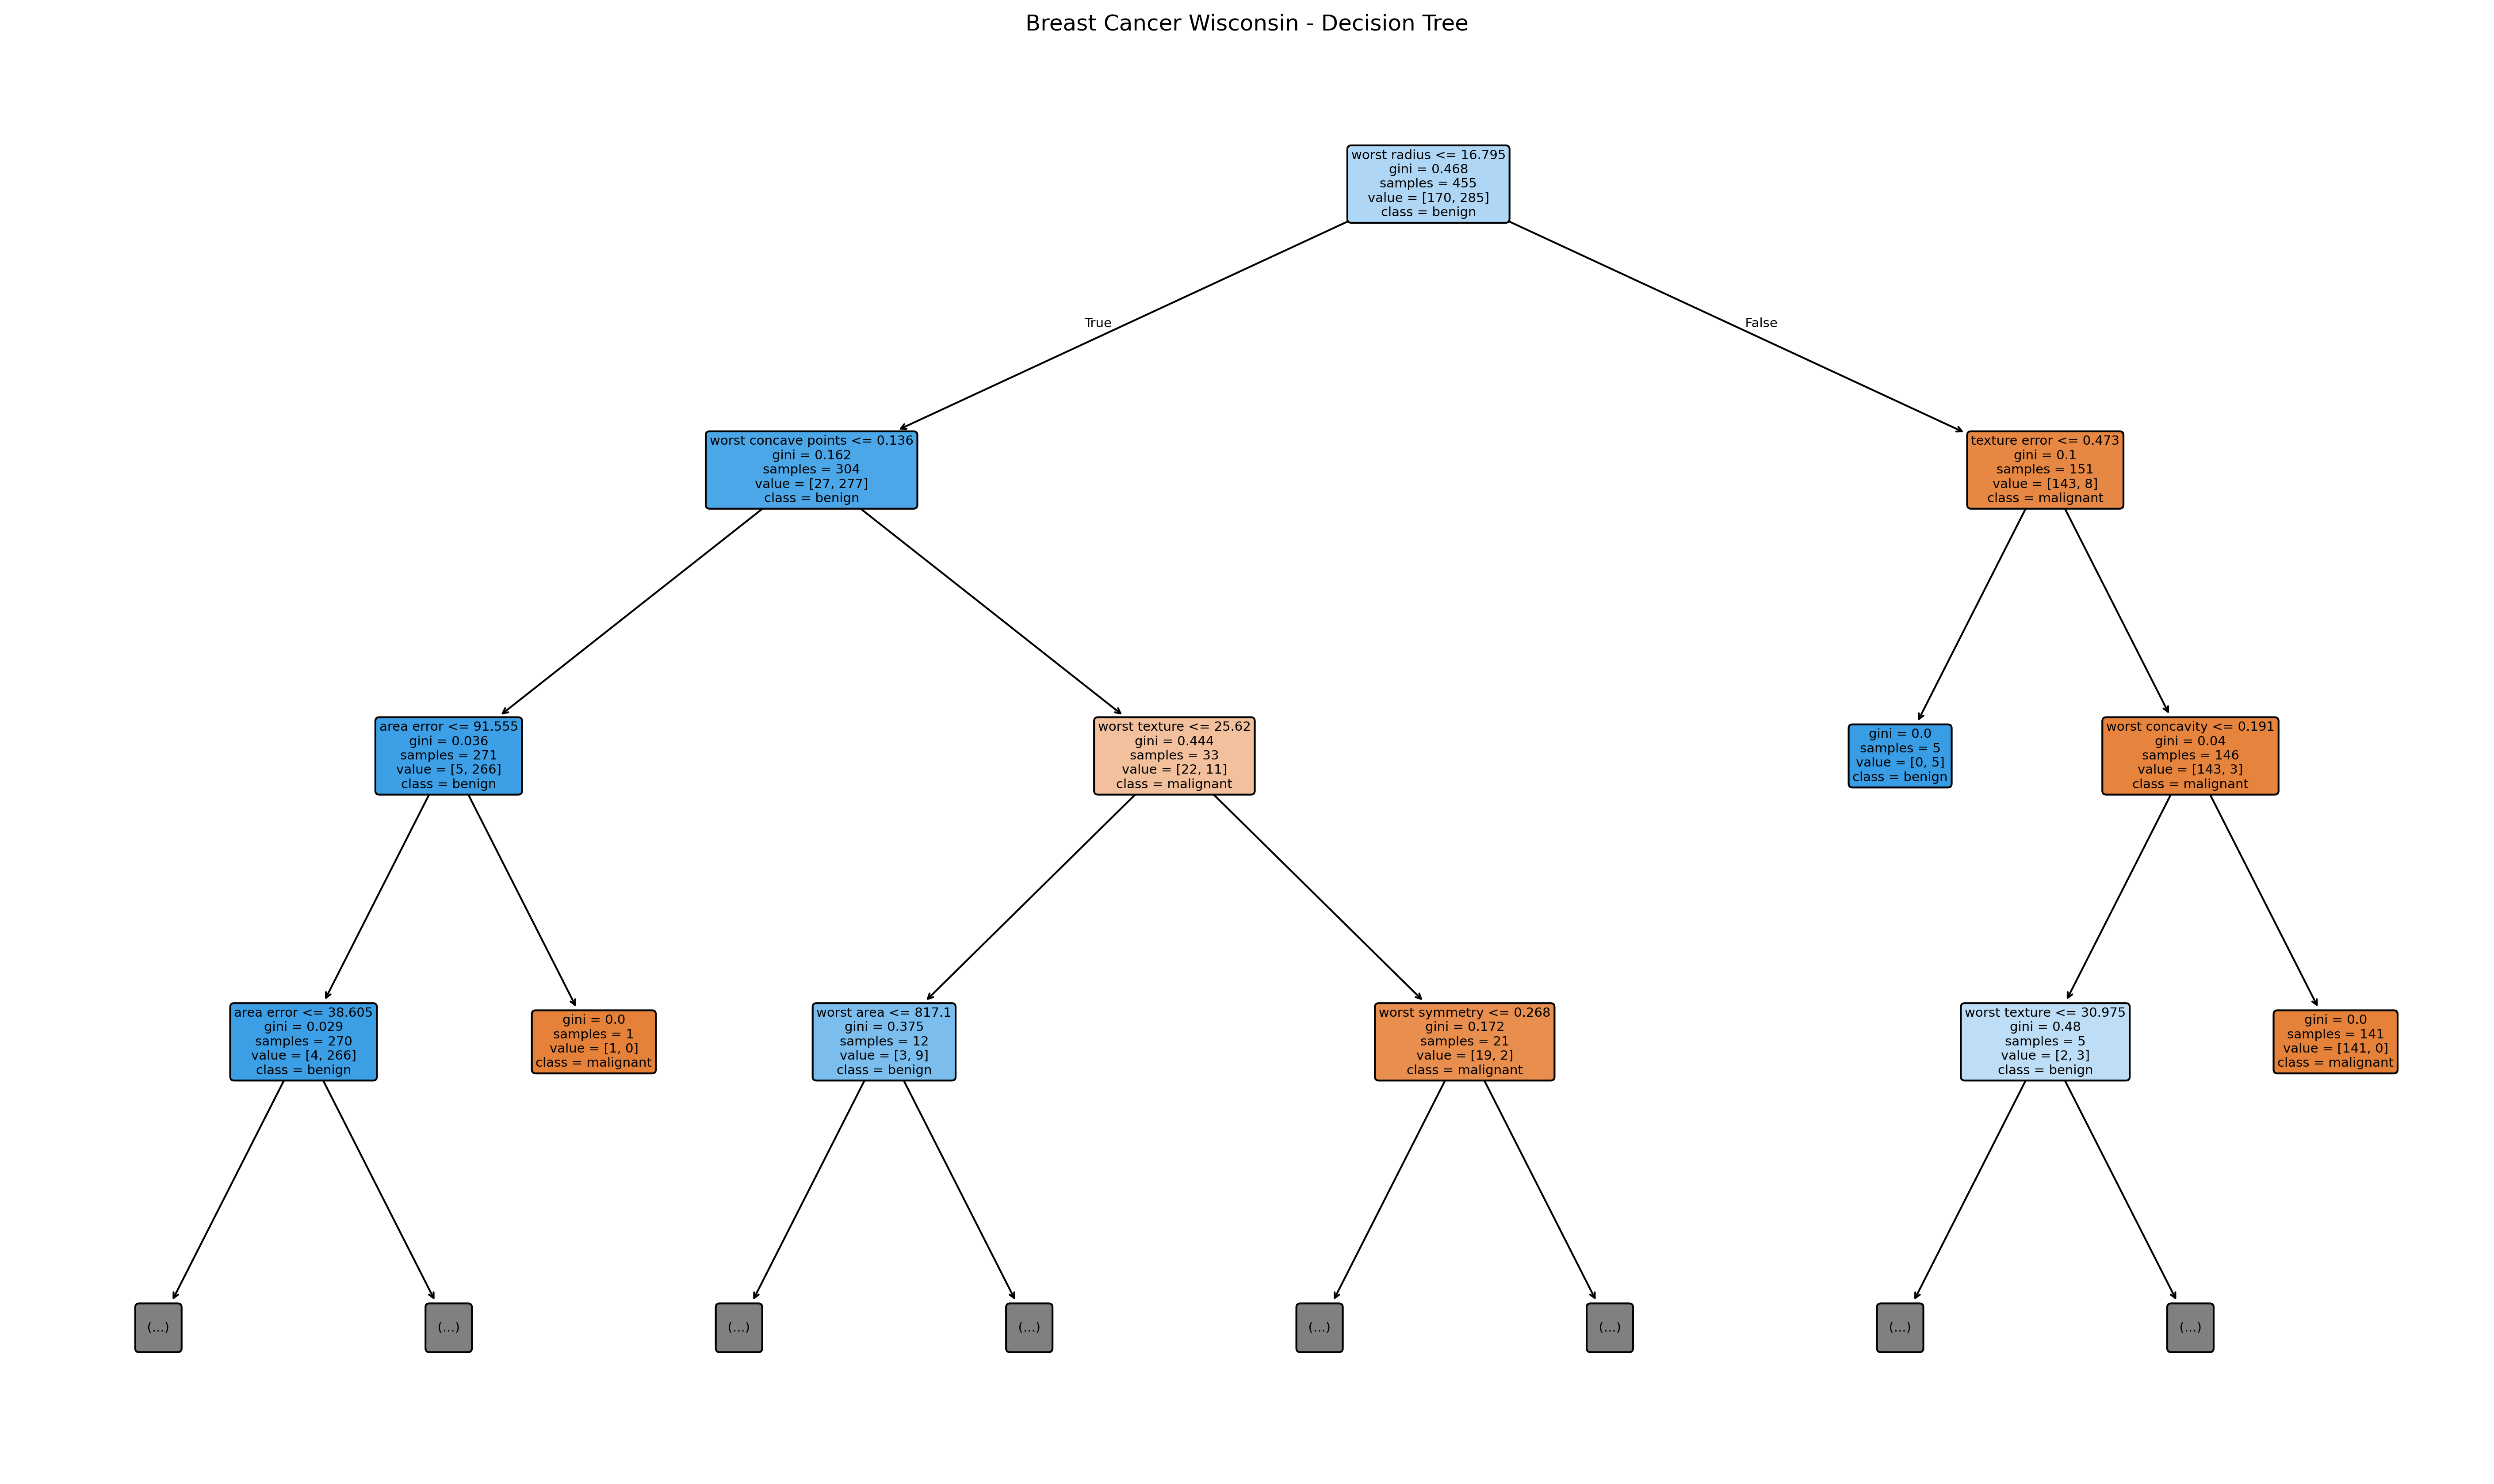

In [7]:

# Decision Tree visualization

plt.figure(figsize=(24, 14), dpi=300)

plot_tree(
    model,
    feature_names=cancer.feature_names,
    class_names=cancer.target_names,
    filled=True,
    rounded=True,
    fontsize=7,
    max_depth=3
)

plt.title("Breast Cancer Wisconsin - Decision Tree")
plt.show()
